# 03 · 四个子集、超参数搜索和不对称损失

`02_modeling.ipynb` 只看 FD001 和默认参数。这里回答三个问题：

1. 换到多工况、多故障模式的子集，流程还成立吗？
2. 超参数搜索的提升有多少是真的？
3. 报晚罚得更重的损失函数，换来了什么，又付出了什么？

结果由 `scripts/train_models.py` 和 `scripts/tune_models.py` 生成。

**怎么读这些数字**

- **嵌套 CV** 评估的是整个选择流程：外层每一折都只用外层训练发动机重新选特征集、参数和权重，再预测留出的发动机。它比选择时的 CV 更可信。它估计的是这个流程的表现，不是最终那一个固定的模型。
- **官方测试集**不参与训练和选择，但开发时看过它的结果，并因此改过验证指标、固定过截顶。所以它是基准，不是独立证明。
- **主要指标 `rmse_near_failure`** 只统计真实 RUL ≤ 125。它看不到健康阶段的低估，所以这里同时报告其他指标。

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rul.data import load_rul, load_trajectories
from rul.evaluate import predict_rul
from rul.experiments import RESULTS_DIR, Experiment, best_experiment, fit_final
from rul.metrics import nasa_score, rmse

BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#c9c8c2", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "text.color": INK, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.edgecolor": GRAY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
pd.set_option("display.width", 200, "display.max_columns", 20)

SUBSETS = ["FD001", "FD002", "FD003", "FD004"]


def load(subset, name):
    return json.loads((RESULTS_DIR / subset / f"{name}.json").read_text(encoding="utf-8"))


final = {s: load(s, "final") for s in SUBSETS}
tuning = {s: load(s, "tuning") for s in SUBSETS}

## 1. 四个子集的结果

In [2]:
pd.DataFrame([{
    "subset": s,
    "default CV": tuning[s]["default"]["cv_rmse_near_failure"],
    "nested CV": final[s]["nested_cv"]["rmse_near_failure"],
    "nested std": final[s]["nested_cv"]["rmse_near_failure_std"],
    "selection CV": final[s]["selection_cv_optimistic"]["rmse_near_failure"],
    "folds better": f'{tuning[s]["paired_vs_default"]["folds_better"]}/5',
    "default test": tuning[s]["default"]["test"]["rmse"],
    "final test": final[s]["test"]["rmse"],
    "final test RUL≤125": final[s]["test"]["rmse_near_failure"],
    "engines RUL>125": f'{final[s]["test"]["n_above_near_failure"]}/{final[s]["test"]["n_engines"]}',
    "features": final[s]["features"],
    "window": final[s]["window"],
    "late weight": final[s]["late_weight"],
} for s in SUBSETS]).round(2)

,subset,default CV,nested CV,nested std,selection CV,folds better,default test,final test,final test RUL≤125,engines RUL>125,features,window,late weight
0,FD001,14.04,11.32,0.83,11.30,5/5,14.57,13.92,12.83,11/100,window_all_columns,50,5
1,FD002,16.46,13.07,0.67,13.07,5/5,26.51,25.82,12.02,57/259,condition_window,50,5
2,FD003,14.16,12.15,0.72,12.08,5/5,15.39,14.32,11.59,15/100,window_all_columns,50,5
3,FD004,16.55,13.76,2.06,13.64,5/5,26.60,26.75,13.09,67/248,condition_window,50,5


In [3]:
pd.DataFrame([
    {"subset": s, "model": c["model"], "features": c["features"], "window": c["window"], "late weight": c["late_weight"]}
    for s in SUBSETS for c in tuning[s]["nested_cv"]["chosen_per_fold"]
]).groupby(["subset", "model", "features", "window", "late weight"]).size().rename("outer folds").reset_index()

,subset,model,features,window,late weight,outer folds
0,FD001,lightgbm_asymmetric,window,50,5.0,3
1,FD001,lightgbm_asymmetric,window_all_columns,50,5.0,2
2,FD002,lightgbm_asymmetric,condition_window,50,5.0,5
3,FD003,lightgbm_asymmetric,condition_window,50,5.0,3
4,FD003,lightgbm_asymmetric,window_all_columns,50,5.0,2
5,FD004,lightgbm,condition_window,50,1.0,1
6,FD004,lightgbm_asymmetric,condition_window,50,5.0,4


**发现**

- **搜索的提升比选择时的 CV 显示的要小一点，但仍然稳定**：嵌套 CV 四个子集都是 5/5 折好于默认配置。这是这组划分上的描述，折数太少，不算显著性检验。选择 CV 只比嵌套 CV 乐观 0–0.12，说明 20 组候选的选择偏差不大。
- **测试 RMSE 没有全部变好**：FD001–FD003 比默认配置低，FD004 从 26.60 变成 26.75。这和第 3 节的权重取舍有关。
- **FD002、FD004 的测试 RMSE 主要被 RUL > 125 的发动机拉高**：22–27% 的测试发动机 RUL 大于 125。第 4 节把它拆开了。这不能说明模型完全没有泛化问题，因为 CV 和测试的 RUL 分布、观测长度都不同。
- **选择结果比较稳定**：窗口在所有外层折都选 50。FD004 有一个外层折回退到普通 LightGBM，其余都选权重 5。特征集在 FD001 和 FD003 上各折不一致，说明这两个候选差别不大。
- **窗口 50 和权重 5 都是搜索范围的上限**，范围再扩大可能还有提升，这里没有测试。

## 2. 截顶的取舍

这张表用相同配置，只改截顶。**这只是敏感性分析，不用来选截顶**：第一版把截顶放进搜索时，所有子集都选了 100，CV 变好，测试却变差，因为主要指标看不到 RUL > 125 的误差。

In [4]:
pd.DataFrame([
    {"subset": s, **row} for s in SUBSETS for row in tuning[s]["cap_sensitivity_cv"]
]).round(2)

,subset,cap,rmse_near_failure,rmse_all_cycles,score_per_100
0,FD001,100,11.62,57.30,175.08
1,FD001,125,11.93,46.10,260.87
2,FD001,150,14.82,38.76,576.69
3,FD002,100,12.92,58.11,228.13
4,FD002,125,13.90,47.20,396.52
5,FD002,150,17.38,40.16,1001.50
6,FD003,100,12.29,98.35,200.40
7,FD003,125,12.68,85.54,290.01
8,FD003,150,15.68,75.08,649.48
9,FD004,100,13.74,89.11,289.48


**发现**：截顶从 150 降到 100 时，只看 RUL ≤ 125 的两个指标都变好，全周期 RMSE 却变差。这说明主要指标天然偏向低截顶，所以不能让它决定截顶。125 是方案阶段确认的值，这张表只说明它的取舍。

## 3. 不对称损失：换来了什么，付出了什么

先看选择时的 CV。每个指标都以权重 1 为 100 做指数，这样才能画在同一个轴上。规则是事先定的：分数至少降 10%，临近故障 RMSE 最多升 5%，满足条件时选分数最低的。

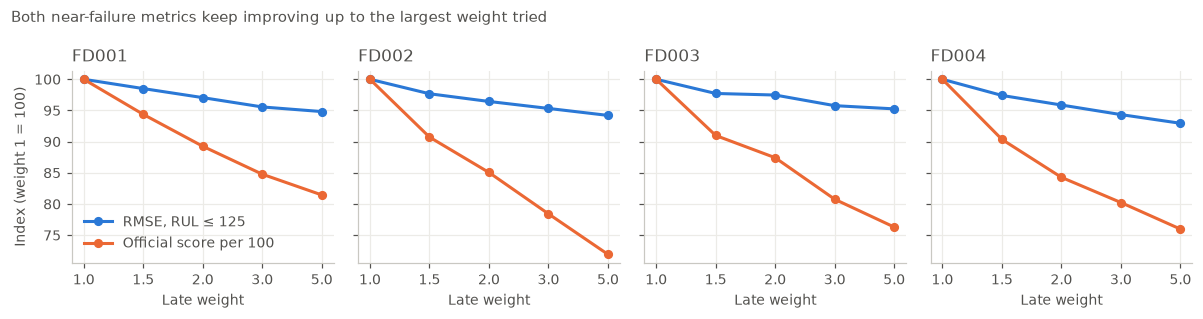

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.9), sharey=True)
for ax, s in zip(axes, SUBSETS):
    weights = pd.DataFrame(tuning[s]["late_weights_cv"])
    x = weights["late_weight"].astype(str)
    ax.plot(x, weights["rmse_near_failure"] / weights["rmse_near_failure"].iloc[0] * 100, color=BLUE, linewidth=2, marker="o", markersize=5, label="RMSE, RUL ≤ 125")
    ax.plot(x, weights["score_per_100"] / weights["score_per_100"].iloc[0] * 100, color=ORANGE, linewidth=2, marker="o", markersize=5, label="Official score per 100")
    ax.set_title(s, loc="left")
    ax.set_xlabel("Late weight")
axes[0].set_ylabel("Index (weight 1 = 100)")
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("Both near-failure metrics keep improving up to the largest weight tried", x=0.01, ha="left", fontsize=10)
plt.tight_layout()

再看官方测试集上的同一个取舍。这里只报告，不改变选择。

In [6]:
pd.DataFrame([{
    "subset": s,
    "symmetric RMSE": tuning[s]["symmetric"]["test"]["rmse"],
    "weighted RMSE": final[s]["test"]["rmse"],
    "symmetric RUL≤125": tuning[s]["symmetric"]["test"]["rmse_near_failure"],
    "weighted RUL≤125": final[s]["test"]["rmse_near_failure"],
    "symmetric score": tuning[s]["symmetric"]["test"]["score"],
    "weighted score": final[s]["test"]["score"],
    "score change %": (final[s]["test"]["score"] / tuning[s]["symmetric"]["test"]["score"] - 1) * 100,
} for s in SUBSETS]).round(2)

,subset,symmetric RMSE,weighted RMSE,symmetric RUL≤125,weighted RUL≤125,symmetric score,weighted score,score change %
0,FD001,13.58,13.92,13.07,12.83,291.36,273.62,-6.09
1,FD002,24.42,25.82,12.71,12.02,4845.03,6756.10,39.44
2,FD003,14.23,14.32,13.10,11.59,394.19,318.05,-19.32
3,FD004,25.43,26.75,13.98,13.09,4015.27,5090.90,26.79


## 4. 误差落在哪里

对每个子集，用全部训练发动机拟合对称模型和最终模型，再看测试集每台发动机最后一个周期的预测。误差 = 预测 - 真实，大于 0 是报晚。这一节是解释，不参与任何选择。

In [7]:
def symmetric_experiment(subset):
    info = tuning[subset]["symmetric"]
    return Experiment("lightgbm", info["features"], 125, subset, window=info["window"],
                      model_params=tuple(info["model_params"].items()), tag="selected")


def last_cycle_outcome(experiment, train, test, true_rul):
    fitted = fit_final(experiment, train)
    table, _ = fitted.featurizer.transform(test)
    last = table.sort_values("cycle").groupby("unit").tail(1).sort_values("unit")
    return pd.DataFrame({
        "true": true_rul.loc[last["unit"]].to_numpy(),
        "predicted": predict_rul(fitted.model, last[fitted.columns]),
        "length": last["cycle"].to_numpy(),
    })


outcomes = []
for s in SUBSETS:
    train, test, true_rul = load_trajectories(s, "train"), load_trajectories(s, "test"), load_rul(s)
    for label, experiment in [("symmetric", symmetric_experiment(s)), ("weighted", best_experiment(s))]:
        outcomes.append(last_cycle_outcome(experiment, train, test, true_rul).assign(subset=s, loss=label))
outcomes = pd.concat(outcomes, ignore_index=True)
outcomes["error"] = outcomes["predicted"] - outcomes["true"]

# 确认这里的预测和结果文件一致
for s in SUBSETS:
    weighted = outcomes[(outcomes["subset"] == s) & (outcomes["loss"] == "weighted")]
    assert abs(rmse(weighted["true"], weighted["predicted"]) - final[s]["test"]["rmse"]) < 1e-3


def summarise(group):
    return pd.Series({
        "engines": len(group),
        "RMSE": rmse(group["true"], group["predicted"]),
        "mean error": group["error"].mean(),
        "score": nasa_score(group["true"], group["predicted"]),
    })


outcomes["RUL band"] = pd.cut(outcomes["true"], [-1, 30, 60, 125, 1000], labels=["≤30", "31–60", "61–125", ">125"])
by_band = (outcomes.groupby(["subset", "RUL band", "loss"], observed=True)[["true", "predicted", "error"]]
           .apply(summarise).round(2))
by_band.unstack("loss")

engines               RMSE          mean error              score         
loss            symmetric weighted symmetric weighted  symmetric weighted symmetric weighted
subset RUL band                                                                             
FD001  ≤30           25.0     25.0      5.06     4.48       1.78     0.88     13.18    10.38
       31–60         14.0     14.0     10.25     9.57       4.71     2.76     29.60    22.19
       61–125        50.0     50.0     16.18    16.05       3.18    -0.04    217.76   195.62
       >125          11.0     11.0     17.18    20.71     -16.54   -19.94     30.83    45.43
FD002  ≤30           61.0     61.0      3.78     3.83       0.48    -1.28     19.91    19.74
       31–60         41.0     41.0      9.82     7.96       4.00     0.30     74.52    43.42
       61–125       100.0    100.0     16.68    16.03       3.71    -1.81    512.64   360.05
       >125          57.0     57.0     46.23    50.17     -41.61   -45.54   4237.96  6332.90
FD003  ≤30           20.0     20.0      2.98     3.16       1.26    -0.75      5.48     5.28
       31–60         21.0     21.0     13.73    12.43       4.54     0.71    130.55    56.13
       61–125        44.0     44.0     15.41    13.47       7.19     2.59    199.58   143.71
       >125          15.0     15.0     19.46    24.63     -17.03   -21.69     58.58   112.93
FD004  ≤30           53.0     53.0      7.07     5.11       3.94     1.46     50.40    28.59
       31–60         38.0     38.0     11.65    10.58       4.46     1.81    190.82   106.02
       61–125        90.0     90.0     17.49    16.79       4.19    -0.69    620.80   533.47
       >125          67.0     67.0     43.19    46.76     -39.01   -42.68   3153.24  4422.82

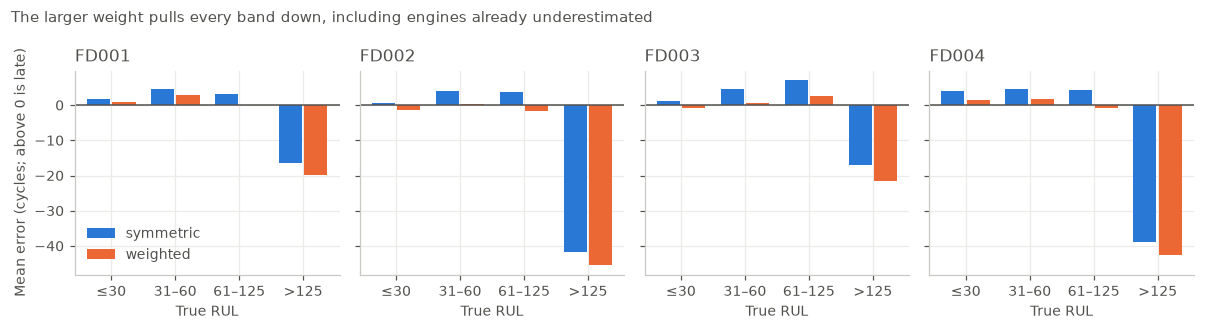

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharey=True)
bands = ["≤30", "31–60", "61–125", ">125"]
for ax, s in zip(axes, SUBSETS):
    positions = np.arange(len(bands))
    for offset, loss, color in [(-0.2, "symmetric", BLUE), (0.2, "weighted", ORANGE)]:
        values = by_band.xs(s, level="subset").xs(loss, level="loss")["mean error"].reindex(bands)
        ax.bar(positions + offset, values, width=0.36, color=color, label=loss)
    ax.axhline(0, color=INK, linewidth=1)
    ax.set_xticks(positions, bands)
    ax.set_title(s, loc="left")
    ax.set_xlabel("True RUL")
axes[0].set_ylabel("Mean error (cycles; above 0 is late)")
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("The larger weight pulls every band down, including engines already underestimated", x=0.01, ha="left", fontsize=10)
plt.tight_layout()

**发现**

- **FD002、FD004 官方分数变差，几乎全部来自 RUL > 125 的发动机**：FD002 这一段从 4238 升到 6333，RUL ≤ 125 的三段合计从 607 降到 423；FD004 这一段从 3153 升到 4423，其余三段合计从 862 降到 668。
- **原因**：权重让预测整体下移。RUL ≤ 125 的报晚因此减少，但 RUL > 125 的发动机本来就因截顶被低估 40 个周期左右，再低估 4 个周期，指数分数就涨得很快。
- **FD001、FD003 没有这个问题**：这段发动机少、低估也小，所以总分数还是变好了。
- **对维修决策的含义**：RUL > 125 的低估是报早，不会造成半路故障，但可能让寿命估计偏短。如果业务关心健康阶段的绝对寿命，这个模型不合适。

再按观测长度分层：历史越短，模型能看到的退化信息越少。这里只看 RUL ≤ 125 的发动机，避开截顶的影响。

In [9]:
near = outcomes[(outcomes["true"] <= 125) & (outcomes["loss"] == "weighted")].copy()
near["observed cycles"] = pd.cut(near["length"], [0, 50, 100, 150, 200, 1000], labels=["≤50", "51–100", "101–150", "151–200", ">200"])
(near.groupby(["subset", "observed cycles"], observed=True)[["true", "predicted", "error"]]
 .apply(summarise)[["engines", "RMSE", "mean error"]].round(2).unstack("subset"))

engines                     RMSE                      mean error                    
subset            FD001 FD002 FD003 FD004  FD001  FD002  FD003  FD004      FD001 FD002  FD003  FD004
observed cycles                                                                                     
≤50                 6.0   9.0   2.0   2.0  11.92  16.93  23.54   4.79       7.31  5.79  14.21   2.89
51–100             17.0  31.0  12.0  20.0  14.49  15.96  13.01  19.56       4.38  4.80   3.60  12.93
101–150            31.0  64.0  27.0  47.0  12.35  11.36  14.03  14.11       3.98  1.22   7.84   5.07
151–200            27.0  67.0  20.0  44.0   9.18   9.61   8.35   9.57      -2.76 -4.30  -2.28  -2.04
>200                8.0  31.0  24.0  68.0  20.12  11.75   8.10  12.07     -13.59 -7.67  -5.16  -4.84

**发现**：观测历史短时，平均误差为正（报晚），历史很长时为负（报早）。比如 FD004 观测 51–100 周期时平均 +12.93，超过 200 周期时 -4.84。模型部分地用“已运行多久”的信息推断寿命，所以短历史的发动机更容易被高估。有些格子只有几台发动机（比如 FD003 ≤50 只有 2 台），不应过度解读。

## 5. 预警表现

预测 RUL 第一次 ≤ 阈值时，这台发动机的真实 RUL 是多少？数字来自嵌套 CV 的外层预测，每台发动机的预测都来自没见过它的整个选择流程。“健康周期”指真实 RUL > 125 的周期。

In [10]:
pd.DataFrame([{"subset": s, **row} for s in SUBSETS for row in final[s]["alerts_nested"]])

,subset,threshold,engines_without_alert,median_rul_at_first_alert,lowest_rul_at_first_alert,first_alert_rul_below_10,first_alert_rul_above_100,healthy_cycle_alert_rate
0,FD001,20,0,20.0,9,1,0,0.0000
1,FD001,30,0,30.0,18,0,0,0.0000
2,FD001,40,0,40.0,27,0,0,0.0000
3,FD001,50,0,49.0,32,0,0,0.0000
4,FD001,60,0,57.0,43,0,0,0.0000
5,FD002,20,0,21.0,11,0,0,0.0000
6,FD002,30,0,31.0,16,0,0,0.0000
7,FD002,40,0,40.0,23,0,0,0.0000
8,FD002,50,0,51.0,31,0,0,0.0000
9,FD002,60,0,60.0,34,0,5,0.0000


**发现**

- **阈值 40 在四个子集上都没有漏报**：每台发动机都在故障前预警过，第一次预警时真实 RUL 的中位数是 39–40，最晚还剩 22–28 个周期。所以界面默认值继续用 40。
- **FD004 最难**：阈值 40 时有 3 台在 RUL > 100 时就第一次预警，健康周期误报率 0.22%；阈值 20 时有 4 台第一次预警已经不到 10 个周期。
- **局限**：这张表只说明预警的时机，没有维修成本模型，所以不能证明 40 是最优阈值，也不能证明总维修成本更低。

## 6. 结论

| 问题 | 答案 | 证据 |
|---|---|---|
| 流程在四个子集上成立吗？ | 成立。多工况子集要先按工况归一化，否则读数被工况切换主导 | 嵌套 CV 11.32、13.07、12.15、13.76 |
| 搜索的提升是真的吗？ | 在这组划分上稳定 | 嵌套 CV 5/5 折好于默认，平均降 2.0–3.4 |
| 不对称损失值得吗？ | 看目标。对临近故障的决策有利，对官方总分不一定 | RUL ≤ 125 测试 RMSE 四个都变好；FD002、FD004 官方分数变差 39%、27% |

**局限**

- 选择规则只看 RUL ≤ 125 的指标，所以权重的代价进不了决策。这是事先定的规则，看到测试结果后没有改。
- 窗口 50 和权重 5 都是搜索范围的上限。
- 嵌套 CV 估计的是流程，不是最终那个模型。内层 3 折，全量选择 5 折，所以两者也不完全相同。
- 官方测试集在开发中看过，只能算基准。
- 没有维修成本模型，也没有显著性检验。
- 仿真数据的结果不能外推到真实设备。